<a href="https://colab.research.google.com/github/ShahriarKamal2/HitPredict-AI-Predicting-Billboard-Hit-Songs-Using-Machine-Learning/blob/main/02_Hit_Song_Modelling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎵 Hit Song Predictor
## Machine Learning Modelling

This notebook develops machine-learning models to predict whether a song
is a hit or non-hit using its audio characteristics.

### Objective

The objective is to train and compare multiple classification algorithms
and identify the model that provides the best predictive performance.

### Target

- `0` = Non-Hit
- `1` = Hit

### Planned Models

1. Dummy Classifier — baseline
2. Logistic Regression
3. Decision Tree
4. Random Forest
5. XGBoost

Models will be compared using accuracy, precision, recall, F1-score,
ROC-AUC and confusion matrices.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os
from sklearn.model_selection import train_test_split

In [2]:
files = glob.glob("/content/dataset-of-*.csv")
print("Number of files found:", len(files))
files

Number of files found: 6


['/content/dataset-of-10s.csv',
 '/content/dataset-of-00s.csv',
 '/content/dataset-of-70s.csv',
 '/content/dataset-of-80s.csv',
 '/content/dataset-of-90s.csv',
 '/content/dataset-of-60s.csv']

In [3]:
#combining the entire dataset
dfs = []
for file in files:
    df_temp = pd.read_csv(file)

    decade = os.path.basename(file)
    df_temp["decade"] = decade
    dfs.append(df_temp)
df = pd.concat(dfs, ignore_index=True)
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (41106, 20)


,track,artist,uri,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,target,decade
0,Wild Things,Alessia Cara,spotify:track:2ZyuwVvV6Z3XJaXIFbspeE,0.741,0.626,1,-4.826,0,0.0886,0.02000,0.000,0.0828,0.706,108.029,188493,4,41.18681,10,1,dataset-of-10s.csv
1,Surfboard,Esquivel!,spotify:track:61APOtq25SCMuK0V5w2Kgp,0.447,0.247,5,-14.661,0,0.0346,0.87100,0.814,0.0946,0.250,155.489,176880,3,33.18083,9,0,dataset-of-10s.csv
2,Love Someone,Lukas Graham,spotify:track:2JqnpexlO9dmvjUMCaLCLJ,0.550,0.415,9,-6.557,0,0.0520,0.16100,0.000,0.1080,0.274,172.065,205463,4,44.89147,9,1,dataset-of-10s.csv
3,Music To My Ears (feat. Tory Lanez),Keys N Krates,spotify:track:0cjfLhk8WJ3etPTCseKXtk,0.502,0.648,0,-5.698,0,0.0527,0.00513,0.000,0.2040,0.291,91.837,193043,4,29.52521,7,0,dataset-of-10s.csv
4,Juju On That Beat (TZ Anthem),Zay Hilfigerrr & Zayion McCall,spotify:track:1lItf5ZXJc1by9SbPeljFd,0.807,0.887,1,-3.892,1,0.2750,0.00381,0.000,0.3910,0.780,160.517,144244,4,24.99199,8,1,dataset-of-10s.csv


In [6]:
#Cleaning up the decade column
decade_mapping = {
    "dataset-of-60s.csv": "1960s",
    "dataset-of-70s.csv": "1970s",
    "dataset-of-80s.csv": "1980s",
    "dataset-of-90s.csv": "1990s",
    "dataset-of-00s.csv": "2000s",
    "dataset-of-10s.csv": "2010s"
}

df["decade"] = df["decade"].replace(decade_mapping)

In [13]:
df["decade"].value_counts().sort_index()

,count
decade,
1960s,8642
1970s,7766
1980s,6908
1990s,5520
2000s,5872
2010s,6398


In [15]:
#creating new column "duration_min"
df["duration_min"] = df["duration_ms"]/60000
df[["duration_ms", "duration_min"]].head()

,duration_ms,duration_min
0,188493,3.141550
1,176880,2.948000
2,205463,3.424383
3,193043,3.217383
4,144244,2.404067


In [16]:
#checking for missing values
missing_values = df.isnull().sum()
missing_values

,0
track,0
artist,0
uri,0
danceability,0
energy,0
key,0
loudness,0
mode,0
speechiness,0
acousticness,0


In [17]:
# checking for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [28]:
features = [
    "danceability",
    "energy",
    "key",
    "loudness",
    "mode",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "time_signature",
    "chorus_hit",
    "sections",
    "duration_min"
]
X = df[features].copy()
y = df["target"].copy()
print("X shape:", X.shape)
print("y shape:", y.shape)

X.head()

X shape: (41106, 15)
y shape: (41106,)


,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,chorus_hit,sections,duration_min
0,0.741,0.626,1,-4.826,0,0.0886,0.02000,0.000,0.0828,0.706,108.029,4,41.18681,10,3.141550
1,0.447,0.247,5,-14.661,0,0.0346,0.87100,0.814,0.0946,0.250,155.489,3,33.18083,9,2.948000
2,0.550,0.415,9,-6.557,0,0.0520,0.16100,0.000,0.1080,0.274,172.065,4,44.89147,9,3.424383
3,0.502,0.648,0,-5.698,0,0.0527,0.00513,0.000,0.2040,0.291,91.837,4,29.52521,7,3.217383
4,0.807,0.887,1,-3.892,1,0.2750,0.00381,0.000,0.3910,0.780,160.517,4,24.99199,8,2.404067


In [20]:
y.value_counts()

,count
target,
1,20553
0,20553


In [22]:
X.select_dtypes(include="object").columns

Index([], dtype='object')

In [24]:
categorical_features = [
    "key",
    "mode",
    "time_signature"
]

numerical_features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "chorus_hit",
    "sections",
    "duration_min"
]
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 12
Categorical features: 3


In [25]:
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify = y
)

In [26]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (32884, 15)
Testing features: (8222, 15)

Training target: (32884,)
Testing target: (8222,)


In [27]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training target distribution:
target
0    0.5
1    0.5
Name: proportion, dtype: float64

Testing target distribution:
target
0    0.5
1    0.5
Name: proportion, dtype: float64


## Modelling Dataset Preparation

The modelling dataset contains audio and structural characteristics of each
song. Track name, artist name and Spotify URI were excluded because the aim
is to predict hit status from musical characteristics rather than artist
identity.

The decade variable was also excluded from the initial predictive model so
that the model focuses on song-level audio characteristics.

The dataset was divided into 80% training data and 20% test data using a
stratified split. Stratification preserves the balanced distribution of hit
and non-hit songs in both subsets.

Numerical and categorical variables will be preprocessed separately within
machine-learning pipelines to prevent information leakage from the test set.

In [30]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [33]:
#creating dummy pipeline
dummy_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DummyClassifier(
                strategy="most_frequent"
            )
        )
    ]
)

In [34]:
dummy_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['danceability', 'energy',
                                                   'loudness', 'speechiness',
                                                   'acousticness',
                                                   'instrumentalness',
                                                   'liveness', 'valence',
                                                   'tempo', 'chorus_hit',
                                                   'sections',
                                                   'duration_min']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['key', 'mode',
                                                   'time_signature'])])),
                ('classifier', DummyClassifier(strategy='most_frequent'))])

In [35]:
dummy_pred = dummy_pipeline.predict(X_test)

In [36]:
dummy_prob = dummy_pipeline.predict_proba(
    X_test
)[:, 1]

In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

In [38]:
dummy_accuracy = accuracy_score(
    y_test,
    dummy_pred
)

dummy_precision = precision_score(
    y_test,
    dummy_pred,
    zero_division=0
)

dummy_recall = recall_score(
    y_test,
    dummy_pred,
    zero_division=0
)

dummy_f1 = f1_score(
    y_test,
    dummy_pred,
    zero_division=0
)

dummy_auc = roc_auc_score(
    y_test,
    dummy_prob
)

In [39]:
print("Dummy Classifier Results")
print("------------------------")

print(f"Accuracy : {dummy_accuracy:.4f}")
print(f"Precision: {dummy_precision:.4f}")
print(f"Recall   : {dummy_recall:.4f}")
print(f"F1 Score : {dummy_f1:.4f}")
print(f"ROC-AUC  : {dummy_auc:.4f}")

Dummy Classifier Results
------------------------
Accuracy : 0.5000
Precision: 0.0000
Recall   : 0.0000
F1 Score : 0.0000
ROC-AUC  : 0.5000


In [40]:
print(
    classification_report(
        y_test,
        dummy_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.50      1.00      0.67      4111
           1       0.00      0.00      0.00      4111

    accuracy                           0.50      8222
   macro avg       0.25      0.50      0.33      8222
weighted avg       0.25      0.50      0.33      8222



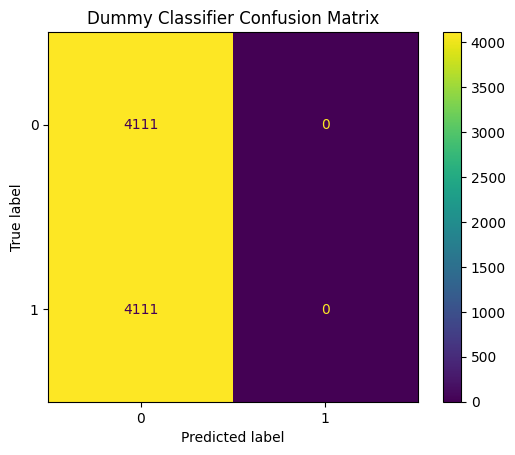

In [41]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    dummy_pred
)

plt.title("Dummy Classifier Confusion Matrix")
plt.show()

In [43]:
from sklearn.linear_model import LogisticRegression
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

In [44]:
logistic_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['danceability', 'energy',
                                                   'loudness', 'speechiness',
                                                   'acousticness',
                                                   'instrumentalness',
                                                   'liveness', 'valence',
                                                   'tempo', 'chorus_hit',
                                                   'sections',
                                                   'duration_min']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['key', 'mode',
                                                   'time_signature'])])),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])

In [45]:
logistic_pred = logistic_pipeline.predict(X_test)
logistic_prob = logistic_pipeline.predict_proba(X_test)[:, 1]

In [46]:
logistic_accuracy = accuracy_score(
    y_test,
    logistic_pred
)

logistic_precision = precision_score(
    y_test,
    logistic_pred
)

logistic_recall = recall_score(
    y_test,
    logistic_pred
)

logistic_f1 = f1_score(
    y_test,
    logistic_pred
)

logistic_auc = roc_auc_score(
    y_test,
    logistic_prob
)

In [47]:
print("Logistic Regression Results")
print("---------------------------")

print(f"Accuracy : {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall   : {logistic_recall:.4f}")
print(f"F1 Score : {logistic_f1:.4f}")
print(f"ROC-AUC  : {logistic_auc:.4f}")

Logistic Regression Results
---------------------------
Accuracy : 0.7178
Precision: 0.6854
Recall   : 0.8052
F1 Score : 0.7405
ROC-AUC  : 0.7939


In [49]:
print(classification_report(y_test,logistic_pred))

              precision    recall  f1-score   support

           0       0.76      0.63      0.69      4111
           1       0.69      0.81      0.74      4111

    accuracy                           0.72      8222
   macro avg       0.72      0.72      0.72      8222
weighted avg       0.72      0.72      0.72      8222



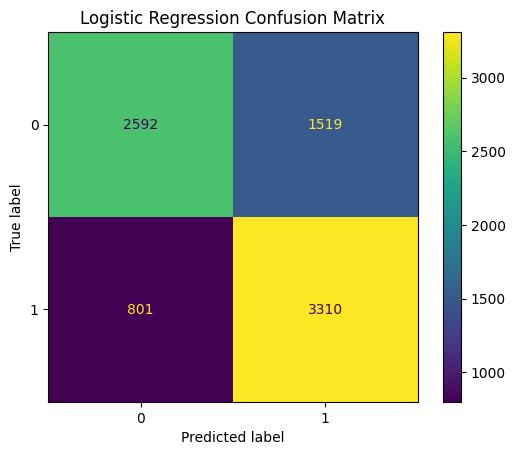

In [50]:
ConfusionMatrixDisplay.from_predictions(y_test,logistic_pred)

plt.title("Logistic Regression Confusion Matrix")

plt.show()

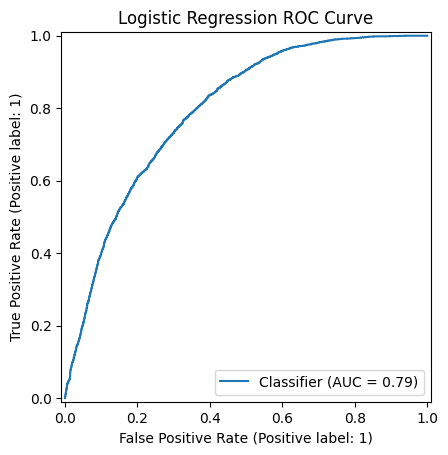

In [51]:
RocCurveDisplay.from_predictions(y_test,logistic_prob)

plt.title(
    "Logistic Regression ROC Curve"
)

plt.show()

In [52]:
initial_results = pd.DataFrame({
    "Model": [
        "Dummy Classifier",
        "Logistic Regression"
    ],

    "Accuracy": [
        dummy_accuracy,
        logistic_accuracy
    ],

    "Precision": [
        dummy_precision,
        logistic_precision
    ],

    "Recall": [
        dummy_recall,
        logistic_recall
    ],

    "F1 Score": [
        dummy_f1,
        logistic_f1
    ],

    "ROC-AUC": [
        dummy_auc,
        logistic_auc
    ]
})


In [53]:
initial_results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Dummy Classifier,0.5000,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.7178,0.6854,0.8052,0.7405,0.7939


### Initial Model Interpretation

The Logistic Regression model substantially outperformed the Dummy Classifier.
While the baseline achieved an ROC-AUC of 0.50, Logistic Regression achieved
an ROC-AUC of approximately 0.794 and an accuracy of 71.78%.

The model achieved a recall of 80.52%, indicating that it successfully
identified the majority of actual hit songs. Its precision was lower at
68.54%, suggesting that some non-hit songs were incorrectly classified as
hits.

The F1-score of 0.741 demonstrates a reasonable balance between precision and
recall. Overall, these results indicate that combining multiple audio
characteristics provides meaningful predictive information about hit status,
although there remains considerable room for improvement using nonlinear
machine-learning models.